In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("Housing.csv")

In [10]:
df.head()
df.info()
df.shape
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [11]:
df.columns.to_list()

['price',
 'area',
 'bedrooms',
 'bathrooms',
 'stories',
 'mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'parking',
 'prefarea',
 'furnishingstatus']

X = input/independent variables
y = target/dependent variable

In [12]:
X = df.drop("price", axis=1)
y = df["price"]

In [13]:
X.head()
y.head()

0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64

In [14]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns

categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical columns:
Index(['area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='str')

Categorical columns:
Index(['mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'prefarea', 'furnishingstatus'],
      dtype='str')


/tmp/ipykernel_20521/3017491986.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns


In [15]:
df.dtypes

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

In [16]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns
print(numerical_cols)
categorical_cols = df.select_dtypes(include=['object','category']).columns
print(categorical_cols)

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='str')
Index(['mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'prefarea', 'furnishingstatus'],
      dtype='str')


/tmp/ipykernel_20521/3930957000.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object','category']).columns


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

In [18]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [20]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=1)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(381, 12)
(164, 12)
(381,)
(164,)


In [21]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [22]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['area','bedrooms','bathrooms',...,'parking','prefarea','furnishingstatus']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of

In [23]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,7070000,6.230049e+06
1,4550000,6.329791e+06
2,5600000,6.600961e+06
3,6125000,5.513264e+06
4,2940000,4.306170e+06
5,3780000,2.994678e+06
6,2450000,2.653642e+06
7,7490000,7.365641e+06
8,2940000,2.368857e+06
9,6440000,4.521640e+06


In [24]:
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

In [25]:
from sklearn.metrics import mean_squared_error

In [26]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)


MAE: 852334.0065495012


In [27]:
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 1365102766597.0703


In [28]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 1168376.1237705392


In [29]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.6646298539852422


In [30]:
print("Model Evaluation")
print("----------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

Model Evaluation
----------------------
MAE  : 852334.0065495012
MSE  : 1365102766597.0703
RMSE : 1168376.1237705392
R²   : 0.6646298539852422


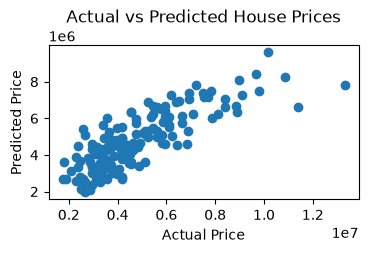

In [31]:
plt.figure(figsize=(4, 2))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

TASK E REGRESSION DIAGNOSTICS

In [32]:
y_pred = model.predict(X_test)
residuals = y_pred - y_test
residuals 

62    -8.399510e+05
247    1.779791e+06
142    1.000961e+06
107   -6.117362e+05
483    1.366170e+06
           ...     
450    9.219548e+05
542    9.205590e+05
408   -6.655673e+05
80    -8.734700e+05
46    -3.434219e+05
Name: price, Length: 164, dtype: float64

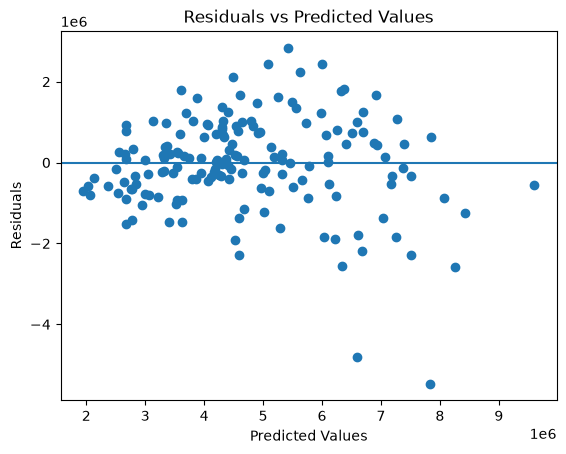

In [33]:
plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

Residual Histogram

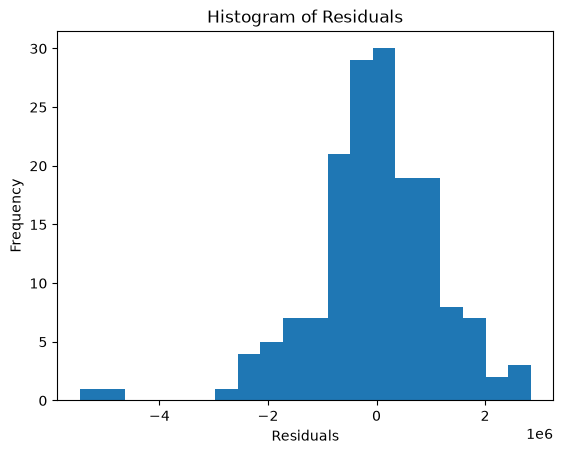

In [34]:
plt.hist(residuals,bins=20)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

Q-Q PLOT Quantile-Quantile Plot

In [35]:
import scipy.stats as stats


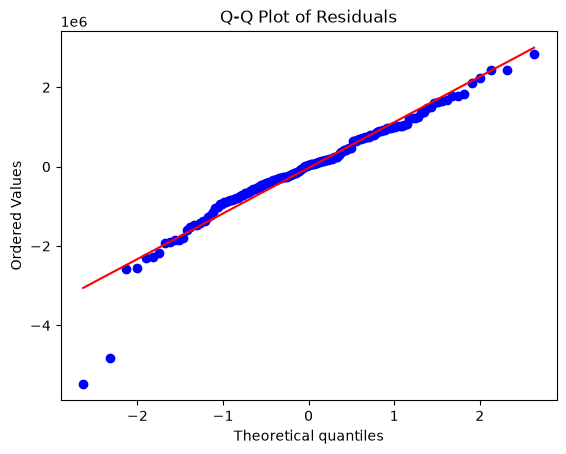

In [36]:
stats.probplot(residuals,dist="norm",plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

VIF CALCULATION

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [40]:
print(vif_data.columns)

Index(['Feature'], dtype='str')


In [42]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_numeric = X.select_dtypes(include="number")

vif_data = pd.DataFrame()
vif_data["Feature"] = X_numeric.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_numeric.values, i)
    for i in range(X_numeric.shape[1])
]

vif_data

,Feature,VIF
0,area,1.170959
1,bedrooms,1.316597
2,bathrooms,1.252775
3,stories,1.255202
4,parking,1.164172


In [43]:
X_numeric = X.select_dtypes(include="number").dropna()

In [44]:
vif_data = pd.DataFrame()
vif_data["Feature"] = X_numeric.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_numeric.values, i)
    for i in range(X_numeric.shape[1])
]

vif_data

,Feature,VIF
0,area,1.170959
1,bedrooms,1.316597
2,bathrooms,1.252775
3,stories,1.255202
4,parking,1.164172
